# Results 1 — Synergy-oriented framework identifies disease-informative feature pairs

Inputs: `../M2_loco_crc_pipeline/results/<data_type>/mdfs_ig_info_<data_type>.csv` (IGs of the per-run top-2 % pairs, 14 folds × 10 MDFS runs).
Outputs: `ig_gain_summary_<data_type>.csv` (per directed pair, mean over the fold–runs in which it was selected; `pair_ig_count` out of 140), `../manuscript/SuppTable2_top30_synergistic_pairs.tsv`, the Wilcoxon test quoted in the text, and the consensus-pairs-only scatter (`figure1b_consensus_pairs_only.png`). The manuscript Figure 1b with all pairs is produced in `figure1b_all_pairs/`.

# Compare MDFS Information Gains: 1D IG vs 2D IG per feature pair

For each **(base, contributing)** pair we compare:
- **base_IG_1D**: the base feature's standalone 1D information gain
- **total_IG**: the base feature's full 2D IG when paired with the contributing feature (`base_IG_1D + IG_2D_added`)

Points above the y = x diagonal indicate that the contributing feature adds synergistic information beyond what the base feature captures alone.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 8)
plt.rcParams["font.size"] = 11

In [2]:
# Load IG data for each analysis type
IG_FILES = {
    "taxa": "../M2_loco_crc_pipeline/results/taxa/mdfs_ig_info_taxa.csv",
    "functions": "../M2_loco_crc_pipeline/results/functions/mdfs_ig_info_functions.csv",
    "combined": "../M2_loco_crc_pipeline/results/combined/mdfs_ig_info_combined.csv",
}

ig_dfs = {}
for dt, path in IG_FILES.items():
    df = pd.read_csv(path)
    ig_dfs[dt] = df
    print(f"{dt}: {len(df)} rows  |  columns: {df.columns.tolist()}")

# Quick sanity check: total_IG should equal base_IG_1D + IG_2D_added
sample = ig_dfs["taxa"].head(3)
print("\nSanity check (taxa, first 3 rows):")
print(sample[["base", "contributing", "base_IG_1D", "IG_2D_added", "total_IG"]].to_string(index=False))

taxa: 107705 rows  |  columns: ['fold', 'test_cohort', 'run', 'base', 'contributing', 'base_IG_1D', 'contributing_IG_1D', 'IG_2D_added', 'total_IG']
functions: 258007 rows  |  columns: ['fold', 'test_cohort', 'run', 'base', 'contributing', 'base_IG_1D', 'contributing_IG_1D', 'IG_2D_added', 'total_IG']


combined: 634168 rows  |  columns: ['fold', 'test_cohort', 'run', 'base', 'contributing', 'base_IG_1D', 'contributing_IG_1D', 'IG_2D_added', 'total_IG']

Sanity check (taxa, first 3 rows):
                       base                contributing  base_IG_1D  IG_2D_added   total_IG
   Abiotrophia_sp_HMSC24B09            Parvimonas_micra    0.049072   360.593994 360.643066
Peptostreptococcus_stomatis    Abiotrophia_sp_HMSC24B09  338.106445    25.112061 363.218506
   Abiotrophia_sp_HMSC24B09 Peptostreptococcus_stomatis    0.049072   363.169434 363.218506


In [3]:
# Aggregate each (base, contributing) pair across folds/runs
# Key comparison: base_IG_1D (1D baseline) vs total_IG (full 2D IG)

DT_ORDER = ["taxa", "functions", "combined"]
pair_stats_by_dt = {}

for dt in DT_ORDER:
    df = ig_dfs[dt]
    ps = df.groupby(["base", "contributing"]).agg(
        base_IG_1D=("base_IG_1D", "mean"),
        contributing_IG_1D=("contributing_IG_1D", "mean"),
        IG_2D_added=("IG_2D_added", "mean"),
        total_IG=("total_IG", "mean"),
        n_obs=("total_IG", "count"),
    ).reset_index()

    # Gain metrics
    ps["gain_abs"] = ps["total_IG"] - ps["base_IG_1D"]           # same as IG_2D_added
    ps["gain_pct"] = ps["gain_abs"] / ps["base_IG_1D"].replace(0, np.nan) * 100

    pair_stats_by_dt[dt] = ps

    n_pos = (ps["gain_abs"] > 0).sum()
    print(f"{dt.upper()}: {len(ps)} pairs | {n_pos}/{len(ps)} ({100*n_pos/len(ps):.1f}%) with positive 2D gain")
    print(ps[["base_IG_1D", "total_IG", "gain_abs", "gain_pct"]].describe().round(3))
    print()

TAXA: 2585 pairs | 2585/2585 (100.0%) with positive 2D gain
       base_IG_1D  total_IG  gain_abs      gain_pct
count    2585.000  2585.000  2585.000  2.582000e+03
mean       78.518   380.336   301.818  7.103762e+04
std       136.919    35.562   136.871  4.148581e+06
min        -0.000   327.935    21.143 -8.699698e+07
25%         2.556   352.271   318.513  8.846510e+02
50%         9.419   363.738   347.260  3.837688e+03
75%        38.340   417.617   404.847  1.494178e+04
max       429.278   526.355   443.550  1.756612e+08

FUNCTIONS: 12544 pairs | 12544/12544 (100.0%) with positive 2D gain
       base_IG_1D   total_IG   gain_abs     gain_pct
count   12544.000  12544.000  12544.000    12544.000
mean       46.610    100.730     54.120     1208.093
std        21.928      6.942     21.137    30455.394
min         0.003     81.828     20.918       18.955
25%        30.973     96.770     36.692       58.324
50%        49.087    100.196     52.637      107.524
75%        63.437    104.159    

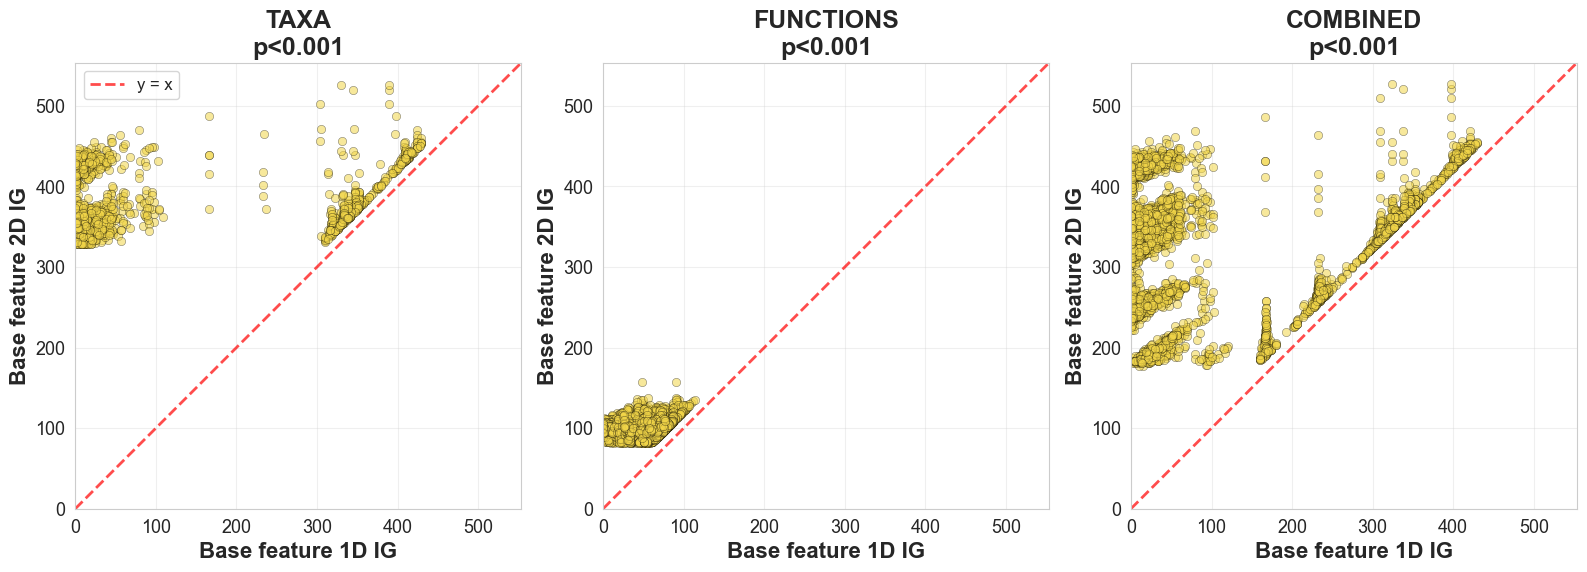

In [4]:
# --- Scatter: base_IG_1D (x) vs total_IG (y) per pair ---
# Points above y=x → contributing feature adds 2D information gain

def _format_p(p: float) -> str:
    if p < 1e-3:
        return "p<0.001"
    if p < 1e-2:
        return f"p={p:.3f}"
    return f"p={p:.2f}"

# Bigger text + taller figure + symmetric panels
TITLE_FS = 18
LABEL_FS = 16
TICK_FS = 13
LEGEND_FS = 12
CBAR_FS = 14

# Global symmetric limits (same x/y range in every panel)
global_max = 0.0
for dt in DT_ORDER:
    ps = pair_stats_by_dt[dt]
    global_max = max(global_max, float(ps["base_IG_1D"].max()), float(ps["total_IG"].max()))

lims = [0, global_max * 1.05]

fig, axes = plt.subplots(1, 3, figsize=(16, 8), sharex=False, sharey=False)
last_sc = None

for ax, dt in zip(axes, DT_ORDER):
    ps = pair_stats_by_dt[dt]

    last_sc = ax.scatter(
        ps["base_IG_1D"], ps["total_IG"],
        color="#F2D649",  # light yellow (match previous look)
        s=36, alpha=0.55, edgecolors="black", linewidth=0.35,
    )

    # Symmetric axes and y=x reference (true 45°)
    ax.set_xlim(lims)
    ax.set_ylim(lims)
    ax.set_aspect("equal", adjustable="box")
    ax.plot(lims, lims, "r--", lw=2.0, alpha=0.7, label="y = x")

    # Paired test (report p only)
    diff = (ps["total_IG"] - ps["base_IG_1D"]).dropna()
    try:
        _, p = stats.wilcoxon(diff)
    except Exception:
        _, p = stats.ttest_rel(ps["total_IG"], ps["base_IG_1D"], nan_policy="omit")

    ax.set_title(f"{dt.upper()}\n{_format_p(float(p))}", fontsize=TITLE_FS, fontweight="bold")
    ax.grid(True, alpha=0.3)
    ax.set_xlabel("Base feature 1D IG", fontsize=LABEL_FS, fontweight="bold")
    ax.set_ylabel("Base feature 2D IG", fontsize=LABEL_FS, fontweight="bold")
    ax.tick_params(axis="both", labelsize=TICK_FS)

axes[0].legend(loc="upper left", fontsize=LEGEND_FS)

# Layout
fig.tight_layout()
plt.savefig("figure1b_consensus_pairs_only.png", dpi=200, bbox_inches="tight")
plt.show()


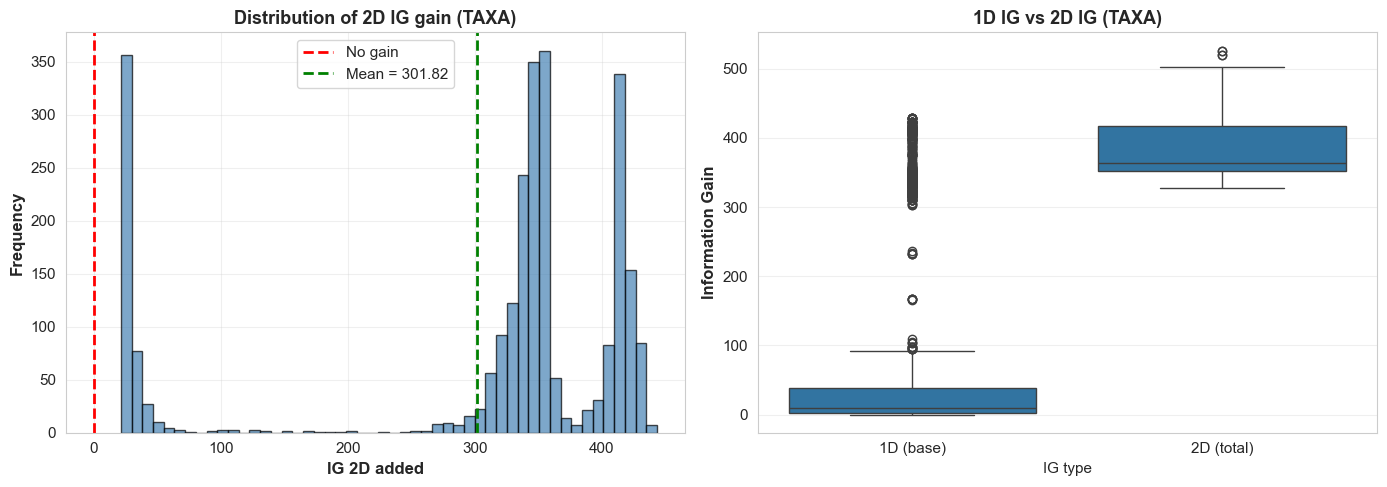

TAXA Wilcoxon signed-rank: W=0.0, p=0.00e+00



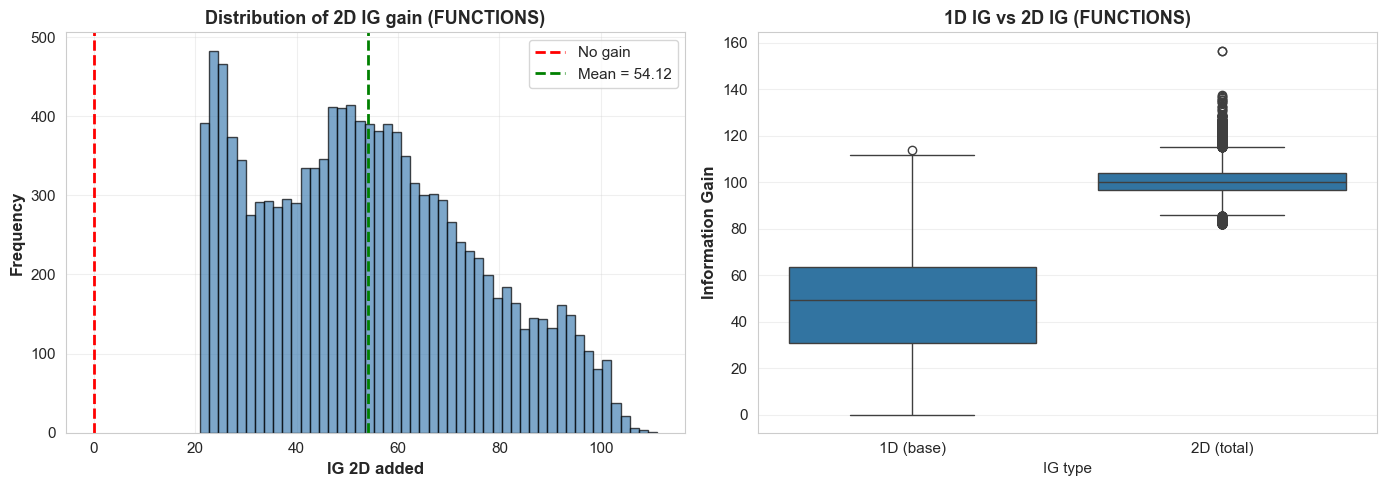

FUNCTIONS Wilcoxon signed-rank: W=0.0, p=0.00e+00



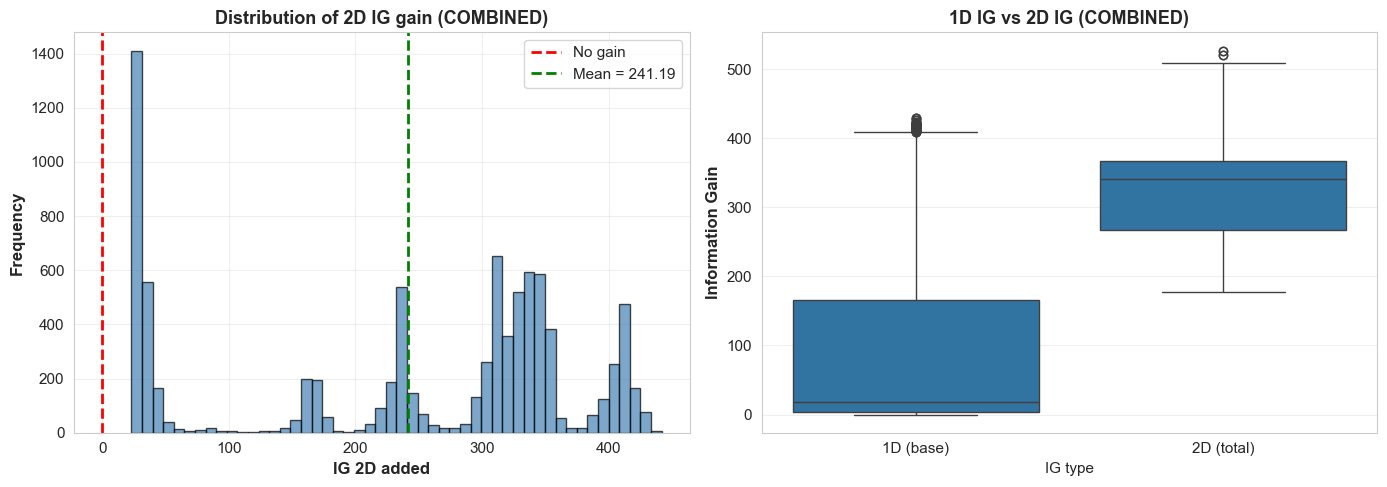

COMBINED Wilcoxon signed-rank: W=0.0, p=0.00e+00



In [5]:
# --- Distribution of 2D gain (IG_2D_added) + boxplot comparison ---

for dt in DT_ORDER:
    ps = pair_stats_by_dt[dt]
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # Histogram of absolute 2D gain
    vals = ps["gain_abs"].dropna()
    axes[0].hist(vals, bins=50, edgecolor="black", alpha=0.7, color="steelblue")
    axes[0].axvline(0, color="red", ls="--", lw=2, label="No gain")
    axes[0].axvline(vals.mean(), color="green", ls="--", lw=2, label=f"Mean = {vals.mean():.2f}")
    axes[0].set_xlabel("IG 2D added", fontsize=12, fontweight="bold")
    axes[0].set_ylabel("Frequency", fontsize=12, fontweight="bold")
    axes[0].set_title(f"Distribution of 2D IG gain ({dt.upper()})", fontsize=13, fontweight="bold")
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)

    # Paired boxplot: 1D vs 2D IG
    box_data = pd.DataFrame({
        "IG type": ["1D (base)"] * len(ps) + ["2D (total)"] * len(ps),
        "IG value": pd.concat([ps["base_IG_1D"], ps["total_IG"]], ignore_index=True),
    })
    sns.boxplot(data=box_data, x="IG type", y="IG value", ax=axes[1])
    axes[1].set_title(f"1D IG vs 2D IG ({dt.upper()})", fontsize=13, fontweight="bold")
    axes[1].set_ylabel("Information Gain", fontsize=12, fontweight="bold")
    axes[1].grid(True, alpha=0.3, axis="y")

    plt.tight_layout()
    plt.show()

    # Paired test
    t, p = stats.wilcoxon((ps["total_IG"] - ps["base_IG_1D"]).dropna())
    print(f"{dt.upper()} Wilcoxon signed-rank: W={t:.1f}, p={p:.2e}\n")

In [6]:
# --- Top pairs by 2D gain (furthest above the diagonal) & save summaries ---
# "points furthest from the diagonal" = largest (total_IG - base_IG_1D) = gain_abs
from IPython.display import display

OUTPUT_FILES = {
    "taxa": "ig_gain_summary_taxa.csv",
    "functions": "ig_gain_summary_functions.csv",
    "combined": "ig_gain_summary_combined.csv",
}

# Total possible observations per pair (14 LOCO folds × 10 MDFS runs)
TOTAL_FOLD_RUNS = 140

all_ranked = []
for dt in DT_ORDER:
    ps = pair_stats_by_dt[dt].sort_values("gain_abs", ascending=False).copy()

    # Rename to match desired output format
    out = pd.DataFrame({
        "data_type": dt,
        "base_feature": ps["base"],
        "contributing_feature": ps["contributing"],
        "base_IG_1D_mean": ps["base_IG_1D"].round(3),
        "total_IG_2D_mean": ps["total_IG"].round(3),
        "ig_difference_raw": ps["gain_abs"].round(3),
        "ig_difference_pct": ps["gain_pct"].round(2),
        "pair_ig_count": ps["n_obs"].astype(int).astype(str) + f"/{TOTAL_FOLD_RUNS}",
    })

    out.to_csv(OUTPUT_FILES[dt], index=False)
    print(f"\n{'='*70}")
    print(f"{dt.upper()} — saved to {OUTPUT_FILES[dt]}")
    print(f"Top 15 pairs (furthest above diagonal):")
    print(out.head(15).to_string(index=False))
    all_ranked.append(out)

# Cross-analysis ranking — sorted by raw IG difference (= distance from diagonal)
all_ranked_df = pd.concat(all_ranked, ignore_index=True)
all_ranked_df = all_ranked_df.dropna(subset=["ig_difference_pct"])
all_ranked_df = all_ranked_df.sort_values("total_IG_2D_mean", ascending=False)

print(f"\n{'='*70}")
print("TOP 30 PAIRS BY IG DIFFERENCE (furthest above diagonal) ACROSS ALL ANALYSES")
print(f"{'='*70}")
display(all_ranked_df.head(30))

# Supplementary Table 2: the 30 pairs above (all data types, ranked by mean total 2D IG)
all_ranked_df.to_csv("ig_gain_summary_all_data_types.csv", index=False)
all_ranked_df.head(30).to_csv("../manuscript/SuppTable2_top30_synergistic_pairs.tsv", sep="\t", index=False)
print("Saved ../manuscript/SuppTable2_top30_synergistic_pairs.tsv")


TAXA — saved to ig_gain_summary_taxa.csv
Top 15 pairs (furthest above diagonal):
data_type                           base_feature    contributing_feature  base_IG_1D_mean  total_IG_2D_mean  ig_difference_raw  ig_difference_pct pair_ig_count
     taxa                     Oribacterium_sinus Fusobacterium_nucleatum            4.419           447.969            443.550           10036.90         9/140
     taxa                      Gemella_sanguinis Fusobacterium_nucleatum            2.754           445.387            442.633           16074.02         9/140
     taxa              Streptococcus_intermedius Fusobacterium_nucleatum            0.752           440.538            439.786           58447.82         9/140
     taxa              Streptococcus_sp_263_SSPC Fusobacterium_nucleatum            3.737           439.948            436.211           11673.87       122/140
     taxa                        GGB2980_SGB3962 Fusobacterium_nucleatum            8.978           445.144           

,data_type,base_feature,contributing_feature,base_IG_1D_mean,total_IG_2D_mean,ig_difference_raw,ig_difference_pct,pair_ig_count
21039,combined,Peptostreptococcus_stomatis,Fusobacterium_nucleatum,323.670,527.221,203.551,62.89,140/140
21578,combined,Fusobacterium_nucleatum,Peptostreptococcus_stomatis,397.197,527.221,130.023,32.74,140/140
2086,taxa,Peptostreptococcus_stomatis,Fusobacterium_nucleatum,330.192,526.355,196.163,59.41,140/140
2093,taxa,Fusobacterium_nucleatum,Peptostreptococcus_stomatis,388.969,526.355,137.387,35.32,140/140
21580,combined,Fusobacterium_nucleatum,Parvimonas_micra,397.197,520.325,123.128,31.00,140/140
21050,combined,Parvimonas_micra,Fusobacterium_nucleatum,337.187,520.325,183.138,54.31,140/140
2095,taxa,Fusobacterium_nucleatum,Parvimonas_micra,388.969,519.453,130.484,33.55,140/140
2088,taxa,Parvimonas_micra,Fusobacterium_nucleatum,344.516,519.453,174.936,50.78,140/140
21582,combined,Fusobacterium_nucleatum,Dialister_pneumosintes,397.197,509.794,112.596,28.35,140/140
21042,combined,Dialister_pneumosintes,Fusobacterium_nucleatum,309.101,509.794,200.693,64.93,140/140


Saved ../manuscript/SuppTable2_top30_synergistic_pairs.tsv
